# Whitecaps FC — Player Scouting & Career Projection Model

Complete scouting analytics pipeline: CatBoost scoring model, aging curve projections, Cortex AI scouting reports, and academy readiness assessment.

## 1. Connect & Load Player Data

In [1]:
import os
from snowflake.snowpark import Session

session = Session.builder.config("connection_name", os.getenv("SNOWFLAKE_CONNECTION_NAME", "demo")).create()
print(f"Connected: {session.get_current_account()} / {session.get_current_role()}")

Initiating login request with your identity provider. A browser window should have opened for you to complete the login. If you can't see it, check existing browser windows, or your OS settings. Press CTRL+C to abort and try again...


Connected: "sfsenorthamerica-tbeg_awswest2" / "ACCOUNTADMIN"


In [2]:
import pandas as pd
import numpy as np

df = session.sql("SELECT * FROM WHITECAPS_DEMO_DB.GOLD_ANALYTICS.PLAYER_STATS ORDER BY PLAYER_ID").to_pandas()
acad_df = session.sql("SELECT * FROM WHITECAPS_DEMO_DB.GOLD_ANALYTICS.ACADEMY_PLAYERS WHERE AGE >= 18  -- IS_MINOR flag is unreliable in source ORDER BY PLAYER_ID").to_pandas()

print(f"Loaded {len(df)} first-team players, {len(acad_df)} eligible academy players")
df[['PLAYER_NAME', 'POSITION', 'AGE', 'GOALS', 'ASSISTS', 'XG', 'MARKET_VALUE_USD']].head(10)

Loaded 30 first-team players, 9 eligible academy players


,PLAYER_NAME,POSITION,AGE,GOALS,ASSISTS,XG,MARKET_VALUE_USD
0,Ryan Gauld,Midfielder,29,4,10,5.9,3787738
1,Brian White,Forward,33,15,8,7.4,2727548
2,Ali Ahmed,Midfielder,21,2,6,5.4,4268956
3,Andres Cubas,Midfielder,22,1,7,2.3,2669598
4,Ranko Veselinovic,Defender,33,1,7,11.2,4369950
5,Tristan Blackmon,Defender,31,2,1,5.1,4766044
6,Sam Adekugbe,Defender,22,1,6,2.5,1856466
7,Russell Teibert,Midfielder,22,4,3,8.5,4259162
8,Damir Kreilach,Forward,20,3,6,4.3,3301310
9,Fafa Picault,Forward,34,12,1,5.4,3403401


## 2. Data Governance Check

Medical records have masking policies — PHI is redacted for non-medical roles.

In [3]:
# Query as a non-medical role so masking policies apply (ACCOUNTADMIN is exempt)
admin_role = session.get_current_role()
session.use_role('WHITECAPS_FRONT_OFFICE')
try:
    medical_df = session.sql("""
        SELECT PLAYER_NAME, INJURY_TYPE, SEVERITY, DIAGNOSIS_DETAIL, BLOOD_TYPE, RTP_STATUS
        FROM WHITECAPS_DEMO_DB.GOLD_ANALYTICS.PLAYER_MEDICAL_RECORDS LIMIT 5
    """).to_pandas()
finally:
    session.use_role(admin_role)
medical_df

,PLAYER_NAME,INJURY_TYPE,SEVERITY,DIAGNOSIS_DETAIL,BLOOD_TYPE,RTP_STATUS
0,Ryan Gauld,Hamstring Strain,Grade 1,*** RESTRICTED — MEDICAL STAFF ONLY ***,***,Active Recovery
1,Brian White,ACL Tear,Grade 2,*** RESTRICTED — MEDICAL STAFF ONLY ***,***,Modified Training
2,Ali Ahmed,Ankle Sprain,Grade 3,*** RESTRICTED — MEDICAL STAFF ONLY ***,***,Full Training
3,Andres Cubas,Quad Contusion,Minor,*** RESTRICTED — MEDICAL STAFF ONLY ***,***,Match Ready
4,Ranko Veselinovic,Concussion,Moderate,*** RESTRICTED — MEDICAL STAFF ONLY ***,***,Surgical Recovery


## 3. Scouting Career Score — CatBoost vs Random Forest

In [4]:
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import LabelEncoder

# Feature engineering
df['GOAL_CONTRIBUTION'] = df['GOALS'] + df['ASSISTS']
df['MINUTES_PER_APPEARANCE'] = np.where(df['APPEARANCES'] > 0, df['MINUTES_PLAYED'] / df['APPEARANCES'], 0)
df['XG_OVERPERFORMANCE'] = df['GOALS'] - df['XG']
df['XA_OVERPERFORMANCE'] = df['ASSISTS'] - df['XA']

# Composite scouting score target
df['SCOUTING_SCORE'] = (
    0.20 * (df['GOAL_CONTRIBUTION'] / df['GOAL_CONTRIBUTION'].max()) +
    0.15 * (df['XG_OVERPERFORMANCE'] / df['XG_OVERPERFORMANCE'].abs().max()) +
    0.15 * (df['XA_OVERPERFORMANCE'] / df['XA_OVERPERFORMANCE'].abs().max()) +
    0.15 * (df['PASS_COMPLETION_PCT'] / 100) +
    0.10 * (df['TACKLES_PER_90'] / df['TACKLES_PER_90'].max()) +
    0.10 * (df['MINUTES_PER_APPEARANCE'] / 90) +
    0.10 * np.where(df['AGE'] <= 24, 1.0, np.where(df['AGE'] <= 28, 0.8, 0.5)) +
    0.05 * df['IS_HOMEGROWN'].astype(int)
) * 100

le = LabelEncoder()
df['POSITION_ENC'] = le.fit_transform(df['POSITION'])

features = ['AGE', 'APPEARANCES', 'GOALS', 'ASSISTS', 'MINUTES_PLAYED',
            'PASS_COMPLETION_PCT', 'TACKLES_PER_90', 'XG', 'XA',
            'POSITION_ENC', 'GOAL_CONTRIBUTION', 'MINUTES_PER_APPEARANCE',
            'XG_OVERPERFORMANCE', 'XA_OVERPERFORMANCE']
X = df[features]
y = df['SCOUTING_SCORE']

# Train CatBoost
cb_model = CatBoostRegressor(iterations=200, depth=4, learning_rate=0.1, loss_function='RMSE', verbose=0)
cb_model.fit(X, y)
cb_scores = cross_val_score(cb_model, X, y, cv=5, scoring='r2')

# Train Random Forest
rf_model = RandomForestRegressor(n_estimators=200, max_depth=6, random_state=42)
rf_model.fit(X, y)
rf_scores = cross_val_score(rf_model, X, y, cv=5, scoring='r2')

print(f'CatBoost R² (5-fold CV): {cb_scores.mean():.3f} ± {cb_scores.std():.3f}')
print(f'Random Forest R² (5-fold CV): {rf_scores.mean():.3f} ± {rf_scores.std():.3f}')

best_model = cb_model if cb_scores.mean() >= rf_scores.mean() else rf_model
best_name = 'CatBoost' if cb_scores.mean() >= rf_scores.mean() else 'Random Forest'
print(f'\nWinner: {best_name}')

df['PREDICTED_SCORE'] = best_model.predict(X)
df['RANK'] = df['PREDICTED_SCORE'].rank(ascending=False).astype(int)

print(f'\nTop 10 players by scouting score:')
print(df[['RANK', 'PLAYER_NAME', 'POSITION', 'AGE', 'PREDICTED_SCORE']]
      .sort_values('RANK').head(10).to_string(index=False))

CatBoost R² (5-fold CV): 0.446 ± 0.368
Random Forest R² (5-fold CV): 0.163 ± 0.620

Winner: CatBoost

Top 10 players by scouting score:
 RANK       PLAYER_NAME   POSITION  AGE  PREDICTED_SCORE
    1    Justin Dhillon    Forward   27        74.811609
    2 Alessandro Schopf Midfielder   25        66.533372
    3        Ryan Gauld Midfielder   29        62.813566
    4    Sergio Cordova    Forward   32        62.485156
    5       Brian White    Forward   33        61.761206
    6      Sam Adekugbe   Defender   22        59.771411
    7    Damir Kreilach    Forward   20        57.674878
    8         Ali Ahmed Midfielder   21        56.740569
    9    Deiber Caicedo Midfielder   20        54.597798
   10      Simon Becher    Forward   33        53.008658


### Feature Importance

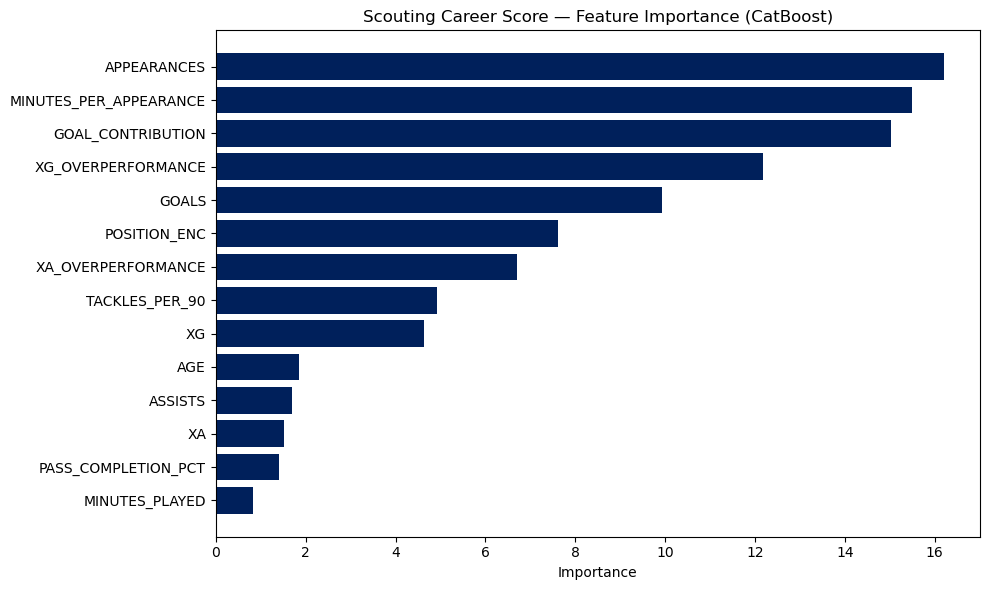

In [5]:
import matplotlib.pyplot as plt

importance = best_model.feature_importances_ if hasattr(best_model, 'feature_importances_') else best_model.get_feature_importance()
feat_imp = pd.DataFrame({'Feature': features, 'Importance': importance}).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feat_imp['Feature'], feat_imp['Importance'], color='#00205B')
ax.set_xlabel('Importance')
ax.set_title(f'Scouting Career Score — Feature Importance ({best_name})')
plt.tight_layout()
plt.show()

## 4. Aging Curve Model — Career Trajectory Projection

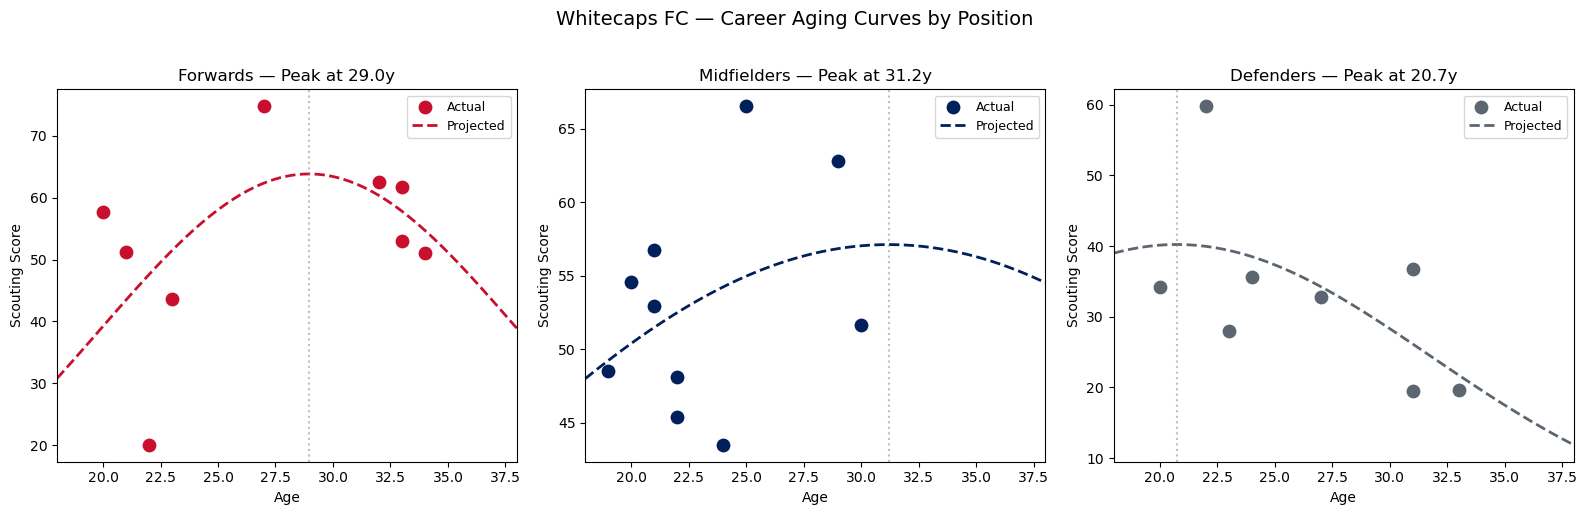

  Position  Peak Age  Peak Score  Decay Rate
   Forward      29.0        63.9      0.0061
Midfielder      31.2        57.1      0.0010
  Defender      20.7        40.2      0.0041


In [6]:
from scipy.optimize import curve_fit

def aging_curve(age, peak_age, peak_val, decay_rate):
    return peak_val * np.exp(-decay_rate * (age - peak_age) ** 2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
positions = ['Forward', 'Midfielder', 'Defender']
colors = ['#C8102E', '#00205B', '#5C6670']
aging_results = []

for idx, pos in enumerate(positions):
    pos_df = df[df['POSITION'] == pos].sort_values('AGE')
    if len(pos_df) < 3:
        continue
    ages = pos_df['AGE'].values.astype(float)
    scores = pos_df['PREDICTED_SCORE'].values
    try:
        popt, _ = curve_fit(aging_curve, ages, scores,
                           p0=[27, scores.max(), 0.01],
                           bounds=([18, 0, 0.001], [35, 200, 0.5]), maxfev=5000)
    except RuntimeError:
        popt = [27.0, scores.mean(), 0.02]

    aging_results.append({'Position': pos, 'Peak Age': round(popt[0], 1),
                          'Peak Score': round(popt[1], 1), 'Decay Rate': round(popt[2], 4)})
    age_range = np.linspace(18, 38, 100)
    ax = axes[idx]
    ax.scatter(ages, scores, color=colors[idx], s=80, zorder=5, label='Actual')
    ax.plot(age_range, aging_curve(age_range, *popt), color=colors[idx], linewidth=2, linestyle='--', label='Projected')
    ax.axvline(x=popt[0], color='gray', linestyle=':', alpha=0.5)
    ax.set_title(f'{pos}s — Peak at {popt[0]:.1f}y')
    ax.set_xlabel('Age')
    ax.set_ylabel('Scouting Score')
    ax.legend(fontsize=9)
    ax.set_xlim(18, 38)

plt.suptitle('Whitecaps FC — Career Aging Curves by Position', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()
print(pd.DataFrame(aging_results).to_string(index=False))

## 5. Write Scores to Snowflake

In [7]:
session.use_database('WHITECAPS_DEMO_DB')
session.use_schema('GOLD_ANALYTICS')

output_df = df[['PLAYER_ID', 'PLAYER_NAME', 'POSITION', 'AGE',
                'PREDICTED_SCORE', 'RANK', 'XG_OVERPERFORMANCE',
                'XA_OVERPERFORMANCE', 'GOAL_CONTRIBUTION']].copy()
output_df.columns = [c.upper() for c in output_df.columns]

sp_df = session.create_dataframe(output_df)
sp_df.write.mode('overwrite').save_as_table('WHITECAPS_DEMO_DB.GOLD_ANALYTICS.SCOUTING_CAREER_SCORES')
print(f'Wrote {len(output_df)} player scores to SCOUTING_CAREER_SCORES')

Wrote 30 player scores to SCOUTING_CAREER_SCORES


## 6. Cortex AI — Scouting Reports

In [8]:
reports_df = session.sql("""
    SELECT
        s.PLAYER_NAME, s.POSITION, s.AGE, ROUND(s.PREDICTED_SCORE, 1) AS SCORE, s.RANK,
        p.MARKET_VALUE_USD, p.CONTRACT_END_DATE, p.IS_DESIGNATED_PLAYER,
        SNOWFLAKE.CORTEX.COMPLETE('claude-sonnet-4-6',
            CONCAT('You are a professional soccer scout for Vancouver Whitecaps FC (MLS). ',
                'Write a concise 3-sentence scouting assessment. Include strengths, areas to watch, and contract recommendation. ',
                'Player: ', s.PLAYER_NAME, ', Position: ', s.POSITION, ', Age: ', s.AGE::VARCHAR,
                ', Score: ', ROUND(s.PREDICTED_SCORE,1)::VARCHAR, '/100',
                ', Goals+Assists: ', s.GOAL_CONTRIBUTION::VARCHAR,
                ', xG Over: ', ROUND(s.XG_OVERPERFORMANCE,1)::VARCHAR,
                ', Value: $', p.MARKET_VALUE_USD::VARCHAR,
                ', Contract: ', p.CONTRACT_END_DATE::VARCHAR,
                ', DP: ', p.IS_DESIGNATED_PLAYER::VARCHAR)
        ) AS AI_SCOUTING_REPORT
    FROM WHITECAPS_DEMO_DB.GOLD_ANALYTICS.SCOUTING_CAREER_SCORES s
    JOIN WHITECAPS_DEMO_DB.GOLD_ANALYTICS.PLAYER_STATS p USING (PLAYER_ID)
    WHERE s.RANK <= 5
    ORDER BY s.RANK
""").to_pandas()

for _, row in reports_df.iterrows():
    print(f"{'='*60}")
    print(f"#{int(row['RANK'])} — {row['PLAYER_NAME']} ({row['POSITION']}, age {row['AGE']})")
    print(f"Score: {row['SCORE']}/100 | Value: ${row['MARKET_VALUE_USD']:,.0f}")
    print(f"\n{row['AI_SCOUTING_REPORT']}\n")

#1 — Justin Dhillon (Forward, age 27)
Score: 74.8/100 | Value: $1,496,595

**Scouting Assessment – Justin Dhillon | Forward | Age 27**

Dhillon demonstrates strong finishing efficiency with a notable xG overperformance of 10.8, suggesting he consistently beats expectation models and contributes meaningfully to the attack with 16 goal contributions, making him a reliable and cost-effective option at the MLS level. At a market value of approximately $1.5M as a non-Designated Player, he represents solid roster value, though his overall score of 74.8/100 indicates room for growth in areas likely tied to link-up play, pressing consistency, or positional versatility that would elevate him to a higher tier forward. **Recommendation:** With his contract running through March 2028, Dhillon is a stable, budget-friendly asset worth retaining as a rotation or starting option — no immediate extension urgency, but the club should monitor his development closely over the next 12 months to determine w

## 7. Academy Prospect Scoring

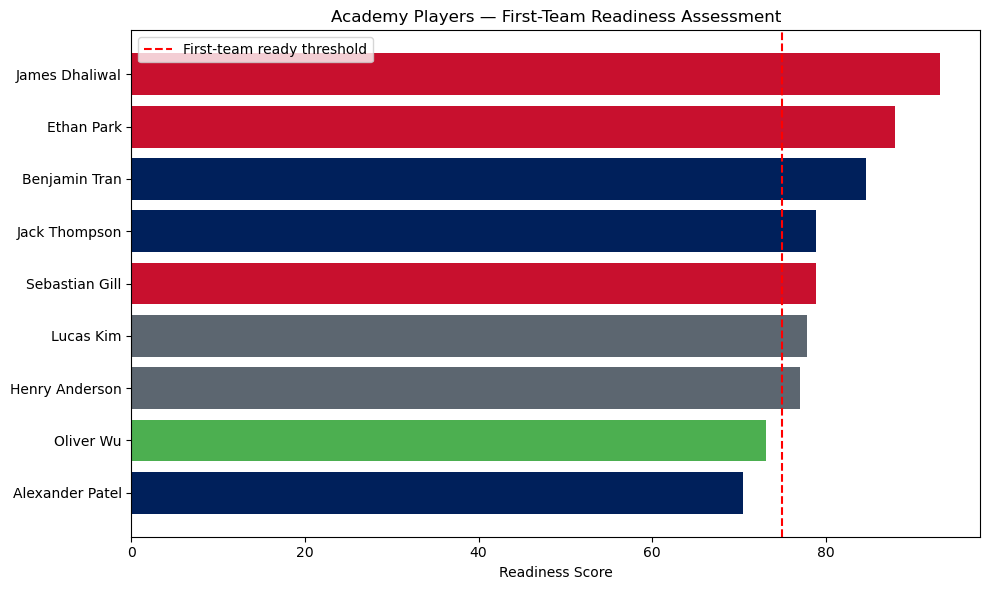


Promotion candidates (7):
   PLAYER_NAME   POSITION  AGE  READINESS_SCORE  SCHOLARSHIP_STATUS
Henry Anderson   Defender   19           77.000 Partial Scholarship
     Lucas Kim   Defender   19           77.875 Partial Scholarship
Sebastian Gill    Forward   19           78.875    Full Scholarship
 Jack Thompson Midfielder   19           78.875 Partial Scholarship
 Benjamin Tran Midfielder   18           84.625    Full Scholarship
    Ethan Park    Forward   18           88.000    Full Scholarship
James Dhaliwal    Forward   18           93.125   Homegrown Pathway


In [9]:
scholarship_weights = {'Homegrown Pathway': 1.0, 'Full Scholarship': 0.9,
                       'Development Contract': 0.7, 'Partial Scholarship': 0.5, 'Trial': 0.3}
acad_df['SCHOLARSHIP_WEIGHT'] = acad_df['SCHOLARSHIP_STATUS'].map(scholarship_weights).fillna(0.3)
acad_df['READINESS_SCORE'] = (
    0.50 * (acad_df['TRAINING_ATTENDANCE_PCT'] / 100) +
    0.25 * (acad_df['GPA'] / 4.0) +
    0.25 * acad_df['SCHOLARSHIP_WEIGHT']
) * 100

acad_df = acad_df.sort_values('READINESS_SCORE', ascending=True)
colors_map = {'Forward': '#C8102E', 'Midfielder': '#00205B', 'Defender': '#5C6670', 'Goalkeeper': '#4CAF50'}
bar_colors = [colors_map.get(p, '#999') for p in acad_df['POSITION']]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(acad_df['PLAYER_NAME'], acad_df['READINESS_SCORE'], color=bar_colors)
ax.axvline(x=75, color='red', linestyle='--', label='First-team ready threshold')
ax.set_xlabel('Readiness Score')
ax.set_title('Academy Players — First-Team Readiness Assessment')
ax.legend()
plt.tight_layout()
plt.show()

candidates = acad_df[acad_df['READINESS_SCORE'] >= 75]
print(f'\nPromotion candidates ({len(candidates)}):')
print(candidates[['PLAYER_NAME', 'POSITION', 'AGE', 'READINESS_SCORE', 'SCHOLARSHIP_STATUS']].to_string(index=False))

## 8. Summary Dashboard

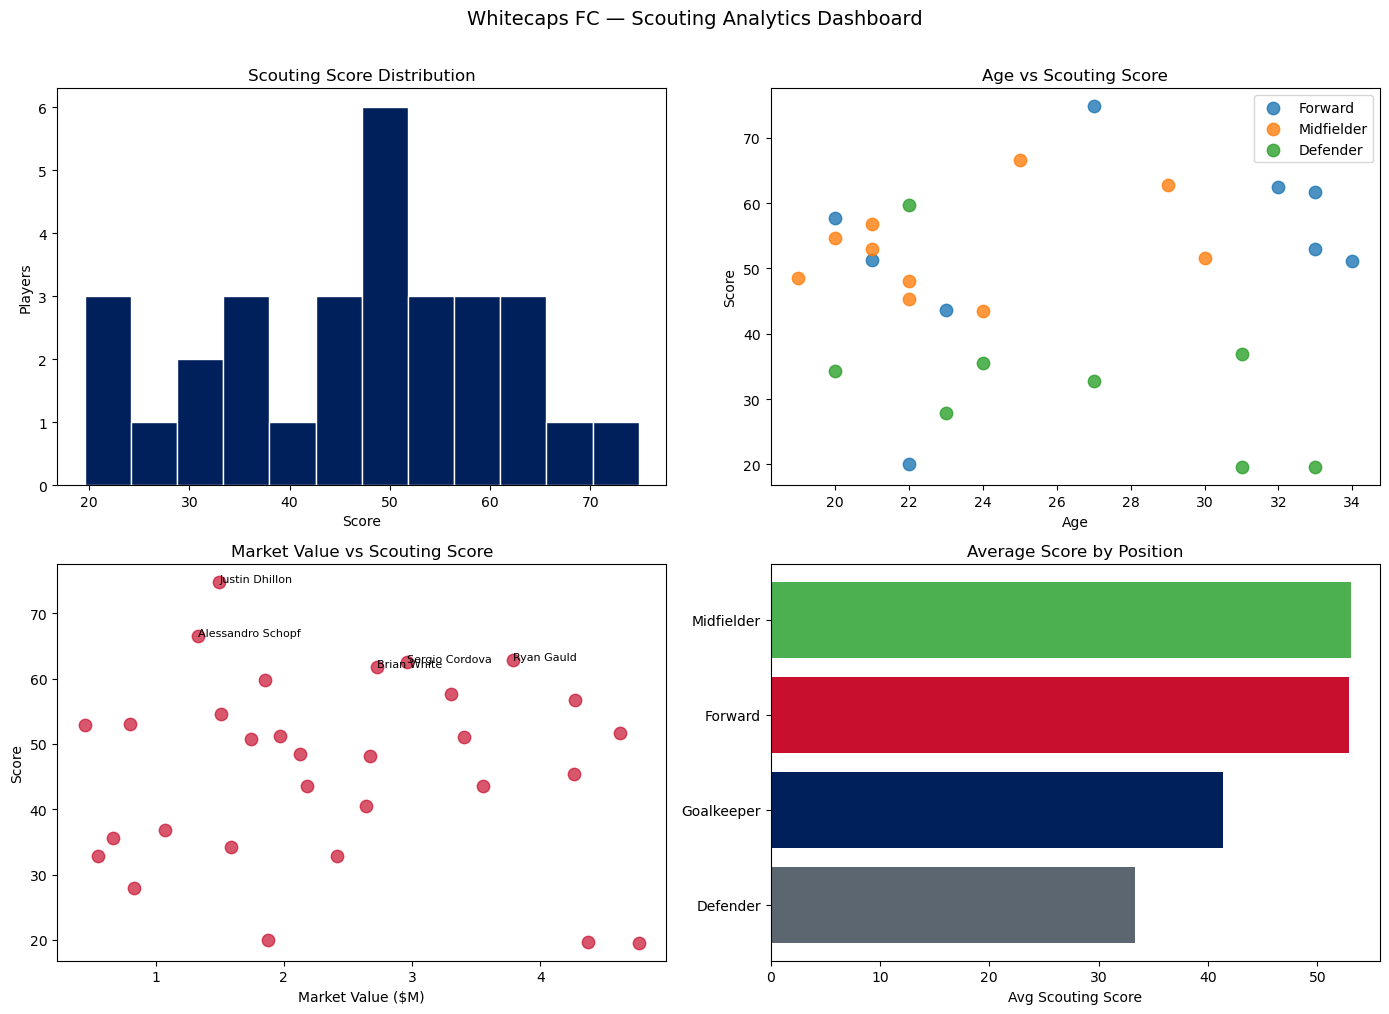

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(df['PREDICTED_SCORE'], bins=12, color='#00205B', edgecolor='white')
axes[0, 0].set_title('Scouting Score Distribution')
axes[0, 0].set_xlabel('Score')
axes[0, 0].set_ylabel('Players')

for pos in ['Forward', 'Midfielder', 'Defender']:
    pdata = df[df['POSITION'] == pos]
    axes[0, 1].scatter(pdata['AGE'], pdata['PREDICTED_SCORE'], label=pos, s=80, alpha=0.8)
axes[0, 1].set_title('Age vs Scouting Score')
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Score')
axes[0, 1].legend()

axes[1, 0].scatter(df['MARKET_VALUE_USD'] / 1e6, df['PREDICTED_SCORE'], c='#C8102E', s=80, alpha=0.7)
for _, row in df[df['RANK'] <= 5].iterrows():
    axes[1, 0].annotate(row['PLAYER_NAME'], (row['MARKET_VALUE_USD']/1e6, row['PREDICTED_SCORE']), fontsize=8)
axes[1, 0].set_title('Market Value vs Scouting Score')
axes[1, 0].set_xlabel('Market Value ($M)')
axes[1, 0].set_ylabel('Score')

pos_avg = df.groupby('POSITION')['PREDICTED_SCORE'].mean().sort_values()
axes[1, 1].barh(pos_avg.index, pos_avg.values, color=['#5C6670', '#00205B', '#C8102E', '#4CAF50'][:len(pos_avg)])
axes[1, 1].set_title('Average Score by Position')
axes[1, 1].set_xlabel('Avg Scouting Score')

plt.suptitle('Whitecaps FC — Scouting Analytics Dashboard', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()